In [2]:
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier
import numpy as np
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.utils.multiclass import unique_labels
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,classification_report
import seaborn as sns

In [3]:
# Carga de datos, interpretando ? como nulo
# https://archive.ics.uci.edu/ml/datasets/heart+disease
df = pd.read_csv('https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data',
names=['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang',
'oldpeak', 'slope', 'ca', 'thal', 'num'],
na_values='?'
)
# Eliminar filas con valores nulos
df.dropna(inplace=True)

# Convertir a problema de clasificación binaria. Atributo target es num, y se distinguen dos casos:
# num=0 (negativo) y num=1 (positivo)
for ind, row in df.iterrows():
    if row['num'] > 0:
        df.at[ind, 'num'] = 1

In [4]:
print(df.shape)
df

(297, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
297,57.0,0.0,4.0,140.0,241.0,0.0,0.0,123.0,1.0,0.2,2.0,0.0,7.0,1
298,45.0,1.0,1.0,110.0,264.0,0.0,0.0,132.0,0.0,1.2,2.0,0.0,7.0,1
299,68.0,1.0,4.0,144.0,193.0,1.0,0.0,141.0,0.0,3.4,2.0,2.0,7.0,1
300,57.0,1.0,4.0,130.0,131.0,0.0,0.0,115.0,1.0,1.2,2.0,1.0,7.0,1


In [5]:
df['num'].value_counts()

num
0    160
1    137
Name: count, dtype: int64

In [6]:
df['num'].value_counts().sort_index()

num
0    160
1    137
Name: count, dtype: int64

<Axes: xlabel='num'>

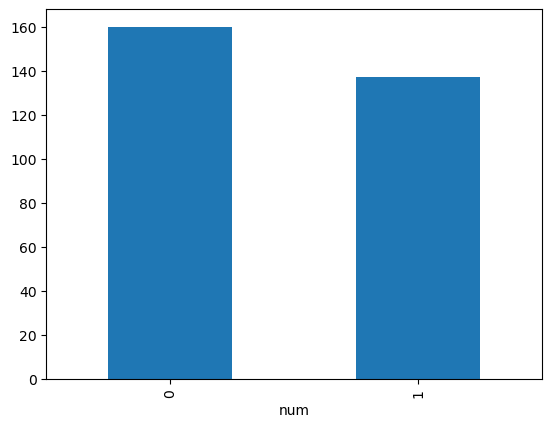

In [7]:
df['num'].value_counts().sort_index().plot(kind='bar')

In [8]:
100 * df['num'].value_counts()/df.shape[0]

num
0    53.872054
1    46.127946
Name: count, dtype: float64

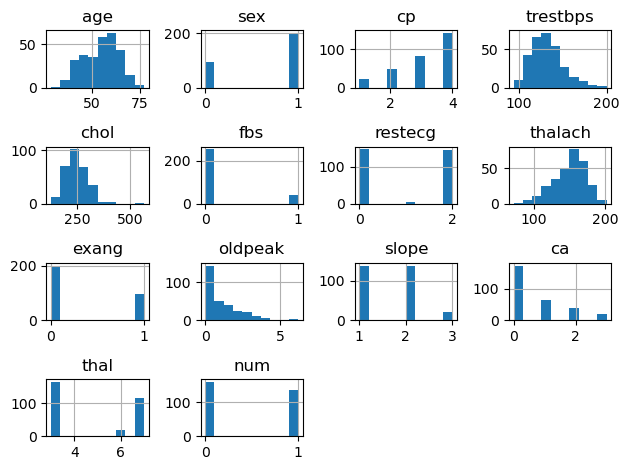

In [9]:
df.hist()
plt.tight_layout ()

## Enunciat

> Entrena un model Naive Bayes per classificar positius i negatius. Treu la tasa d'encerts. 

> Fes una graella de gràfics de campanes de Gauss per a cada variable per visualitzar la seua influència a la decisió. Reflexiona si la seua distribució que has vist a l'histograma ha ajudat o no al model en la predicció. 